# Parte 5: Comparação com K-Means e PCA
**Responsável:** Herbe · Projeto final de Aprendizado Não Supervisionado (SOM)

**Objetivo desta etapa:** verificar se os clusters do SOM (Parte 4) se sustentam quando comparados a duas técnicas mais simples:
- **K-Means direto nos clientes** (`X_scaled`), com o mesmo k = 3;
- **PCA em 2 componentes**, como forma linear de "achatar" os 6 gastos num plano.

Métricas: **silhouette** de cada agrupamento, **Adjusted Rand Index (ARI)** entre eles, ARI com o `Channel` e a variância
explicada pelo PCA. Acrescentamos um teste de **estabilidade** (o resultado muda se trocarmos a semente?).

## 1. Bibliotecas e dados

In [1]:
import os, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from minisom import MiniSom

SEED = 42
np.random.seed(SEED)

# Paleta do projeto (a mesma da Parte 1)
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
COR_CANAL = {"Horeca": AZUL, "Varejo": LARANJA}
DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#d95926", "#f0efec", "#2a78d6"])
# Clusters: cores diferentes das do canal, para não confundir "cluster" com "Horeca/Varejo"
COR_CLUSTER = ["#1baf7a", "#6250d6", "#eda100"]          # aqua, violeta, amarelo
MARCA_CLUSTER = ["o", "s", "^"]
CINZAS = LinearSegmentedColormap.from_list("cinzas", ["#f4f4f2", "#52514e"])   # U-Matrix: escuro = distância maior

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.edgecolor": "#888", "axes.labelcolor": "#222", "xtick.color": "#444", "ytick.color": "#444",
})
os.makedirs("figuras", exist_ok=True)

GASTOS = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
X_scaled = pd.read_csv("dados/X_scaled.csv").values
df = pd.read_csv("dados/dados_preprocessados.csv")
print("X_scaled:", X_scaled.shape, "| df:", df.shape)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.optimize import linear_sum_assignment

clusters = pd.read_csv("dados/clusters.csv")
cl_som = clusters["cluster"].values
K = int(cl_som.max() + 1)
print("k do Ruan:", K, "| tamanhos:", np.bincount(cl_som).tolist())

X_scaled: (440, 6) | df: (440, 16)
k do Ruan: 3 | tamanhos: [203, 93, 144]


## 2. K-Means direto nos clientes (mesmo k)

In [2]:
km = KMeans(n_clusters=K, random_state=SEED, n_init=10).fit(X_scaled)

# Os números dos clusters do K-Means são arbitrários. Para comparar cores e tabelas, renumeramos o K-Means
# para casar com o SOM (casamento que maximiza a concordância). Isso NÃO altera o ARI nem o silhouette.
tab = pd.crosstab(cl_som, km.labels_)
lin, col = linear_sum_assignment(-tab.values)
renum = {c: l for l, c in zip(lin, col)}
cl_km = np.array([renum[c] for c in km.labels_])

cruz = pd.crosstab(pd.Series(cl_som, name="SOM"), pd.Series(cl_km, name="K-Means"), margins=True, margins_name="total")
cruz

K-Means,0,1,2,total
SOM,,,,
0,190,8,5,203
1,4,72,17,93
2,19,0,125,144
total,213,80,147,440


**Leitura:** os dois métodos concordam em **88% dos clientes** (387 de 440, a diagonal da tabela). As discordâncias são poucas e
têm direção clara:
- 19 clientes que o SOM pôs no cluster 2 (grandes mistos) o K-Means mandou para o cluster 0 (Horeca);
- 17 do cluster 1 do SOM (Varejo de mercearia) o K-Means mandou para o cluster 2.

São clientes de fronteira, como o gráfico do PCA mostra abaixo.

In [3]:
def perfil(rotulos):
    b = df.assign(c=rotulos)
    t = b.groupby("c")[GASTOS].median().round(0).astype(int)
    t.insert(0, "clientes", b["c"].value_counts().sort_index())
    t["% Varejo"] = (b.groupby("c")["Canal"].apply(lambda s: (s == "Varejo").mean()) * 100).round(0).astype(int)
    return t

print("Mediana dos gastos (valores reais), clusters do SOM:"); display(perfil(cl_som))
print("Mediana dos gastos (valores reais), clusters do K-Means:"); display(perfil(cl_km))

Mediana dos gastos (valores reais), clusters do SOM:


,clientes,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,% Varejo
c,,,,,,,,
0,203,9351,1492,2067,2046,246,684,1
1,93,2362,6380,10518,425,4196,531,68
2,144,12630,6726,9278,2506,2508,1860,53


Mediana dos gastos (valores reais), clusters do K-Means:


,clientes,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,% Varejo
c,,,,,,,,
0,213,9612,1601,2155,2121,274,686,1
1,80,1492,6300,10502,376,4218,434,60
2,147,12126,7184,9965,2005,3378,2005,62


**Leitura:** **os três perfis são os mesmos nos dois métodos.** As medianas em valores reais quase coincidem:
- cluster 0: Fresh ≈ 9.400-9.600, Grocery ≈ 2.100, 1% Varejo;
- cluster 1: Grocery ≈ 10.500, Fresh e Frozen baixos;
- cluster 2: alto em tudo, com o total mais alto.

A diferença está na borda do cluster 1. O K-Means deixa nele só os clientes com quase nenhum frescos (mediana de Fresh 1.492 contra
2.362 no SOM) e por isso fica menor (80 contra 93). Os nomes que a Parte 6 der aos perfis valem para os dois métodos.

## 3. PCA em 2 componentes

In [4]:
pca = PCA(n_components=2, random_state=SEED).fit(X_scaled)
Z = pca.transform(X_scaled)
var = pca.explained_variance_ratio_
print(f"Variância explicada: PC1 = {var[0]:.1%} | PC2 = {var[1]:.1%} | total = {var.sum():.1%}")
print("Com 3 componentes:", f"{PCA(3).fit(X_scaled).explained_variance_ratio_.sum():.1%}")
cargas = pd.DataFrame(pca.components_.T, index=GASTOS, columns=["PC1", "PC2"]).round(2)
cargas

Variância explicada: PC1 = 44.1% | PC2 = 27.2% | total = 71.3%
Com 3 componentes: 82.0%


,PC1,PC2
Fresh,-0.11,0.59
Milk,0.54,0.13
Grocery,0.57,-0.01
Frozen,-0.14,0.59
Detergents_Paper,0.55,-0.07
Delicassen,0.21,0.53


**Leitura:** dois componentes explicam **71% da variância** (82% com três).
- **PC1 (44%)** tem pesos de 0,54 a 0,57 em `Milk`, `Grocery` e `Detergents_Paper`: é o eixo **mercearia/limpeza**.
- **PC2 (27%)** tem pesos de 0,53 a 0,59 em `Fresh`, `Frozen` e `Delicassen`: é o eixo **perecíveis/delicatessen**.

São exatamente os dois eixos que os component planes do SOM mostraram (Parte 3). Isso confirma os eixos, mas também diz uma coisa
que o relatório precisa admitir: **a estrutura principal desta base é quase linear**, e o PCA, que é linear, já a encontra. O SOM não
"descobre" eixos que o PCA não veja. A vantagem dele está em outro lugar (ver a tabela de prós e contras).

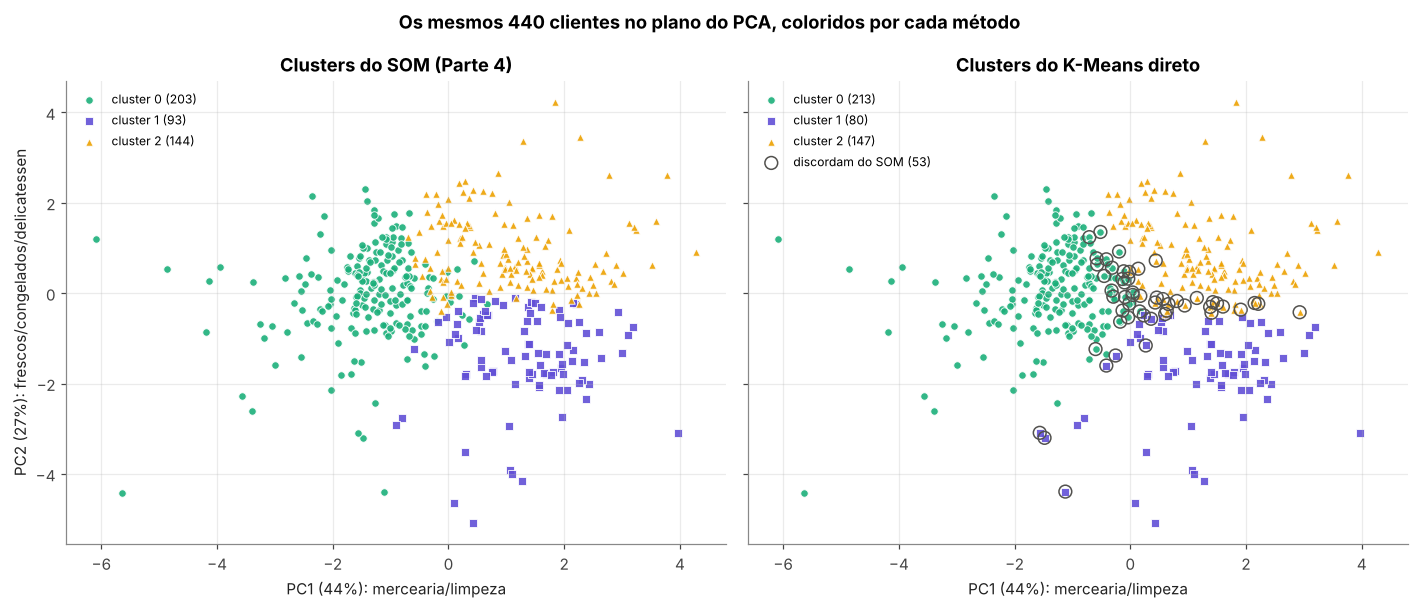

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), sharex=True, sharey=True)
for ax, rot, titulo in [(axes[0], cl_som, "Clusters do SOM (Parte 4)"), (axes[1], cl_km, "Clusters do K-Means direto")]:
    for c in range(K):
        m = rot == c
        ax.scatter(Z[m, 0], Z[m, 1], s=24, marker=MARCA_CLUSTER[c], color=COR_CLUSTER[c], edgecolor="white",
                   linewidth=0.6, label=f"cluster {c} ({m.sum()})", alpha=0.9)
    ax.set_title(titulo); ax.set_xlabel(f"PC1 ({var[0]:.0%}): mercearia/limpeza")
    ax.legend(frameon=False, loc="upper left", fontsize=8)
axes[0].set_ylabel(f"PC2 ({var[1]:.0%}): frescos/congelados/delicatessen")
# pontos onde os dois métodos discordam
dif = cl_som != cl_km
axes[1].scatter(Z[dif, 0], Z[dif, 1], s=70, facecolor="none", edgecolor=CINZA, linewidth=1,
                label=f"discordam do SOM ({dif.sum()})")
axes[1].legend(frameon=False, loc="upper left", fontsize=8)
fig.suptitle("Os mesmos 440 clientes no plano do PCA, coloridos por cada método", fontweight="bold")
plt.tight_layout(); plt.savefig("figuras/05_pca_som_vs_kmeans.png", bbox_inches="tight"); plt.show()

**Leitura:**
- No plano do PCA, os clusters ficam **lado a lado, sem espaço vazio entre eles**:
  - cluster 0 à esquerda (pouca mercearia);
  - cluster 1 embaixo à direita (muita mercearia, poucos perecíveis);
  - cluster 2 em cima à direita (muito de tudo).
- Os 53 clientes em que os métodos discordam (círculos) ficam quase todos **no encontro dos três grupos, perto do centro do gráfico**.
  É a mesma "zona de transição" que a U-Matrix mostrou no meio do mapa.
- Os pontos mais isolados nas bordas (PC2 < −4 ou PC1 < −5) são, em 5 de 6 casos, outliers da Parte 4: clientes com gasto quase
  nulo em alguma categoria.

## 4. Métricas

In [6]:
canal = df["Channel"].values
metricas = pd.DataFrame({
    "silhouette (em X_scaled)": [silhouette_score(X_scaled, cl_som), silhouette_score(X_scaled, cl_km)],
    "ARI com o Channel": [adjusted_rand_score(canal, cl_som), adjusted_rand_score(canal, cl_km)],
    "tamanhos": [np.bincount(cl_som).tolist(), np.bincount(cl_km).tolist()],
}, index=["SOM + K-Means nos pesos", "K-Means direto"])
display(metricas.round(3))
ari = adjusted_rand_score(cl_som, cl_km)
print(f"ARI entre SOM e K-Means: {ari:.3f}  |  concordância simples: {(cl_som == cl_km).mean():.1%}")

,silhouette (em X_scaled),ARI com o Channel,tamanhos
SOM + K-Means nos pesos,0.224,0.317,"[203, 93, 144]"
K-Means direto,0.259,0.350,"[213, 80, 147]"


ARI entre SOM e K-Means: 0.682  |  concordância simples: 88.0%


**Leitura:**
- **O K-Means direto tem silhouette um pouco maior (0,259 contra 0,224).** Isso era esperado: o K-Means
  otimiza diretamente a compactação dos grupos no espaço dos clientes, que é o que o silhouette mede. O SOM agrupa neurônios e
  "herda" a suavização do mapa.
- Os dois valores são baixos (< 0,3). Nenhum método encontra grupos bem separados, porque eles não existem nesta base.
- **ARI SOM × K-Means = 0,68**, uma concordância substancial, mas não total (88% dos clientes no mesmo grupo).
- **ARI com o `Channel` ≈ 0,32-0,35** nos dois. É baixo porque k = 3 e o canal tem 2 classes: o cluster 2 mistura os dois canais
  de propósito, e essa é justamente a informação nova.

## 5. Estabilidade: o resultado muda com a semente?
Repetimos cada método com 10 sementes diferentes e medimos o ARI de cada repetição contra o resultado oficial (semente 42).
ARI = 1 significa partição idêntica.
- **SOM:** treina o mapa de novo com a mesma configuração (`sigma = 2.0`, `learning_rate = 0.3`) e roda o K-Means nos pesos com k = 3.
- **K-Means direto:** só troca o `random_state`.

,SOM,K-Means direto
mean,0.713,0.979
min,0.587,0.951
max,0.797,0.994


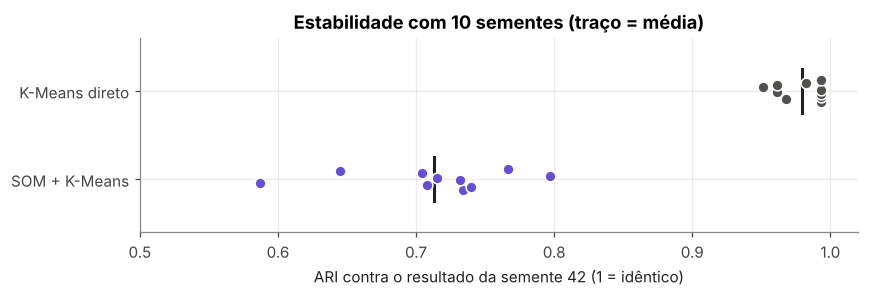

In [7]:
estab = []
for s in range(10):
    m = MiniSom(10, 10, X_scaled.shape[1], sigma=2.0, learning_rate=0.3, random_seed=s)
    m.pca_weights_init(X_scaled); m.train_random(X_scaled, 5000)
    b = np.array([m.winner(x) for x in X_scaled]); ib = b[:, 0] * 10 + b[:, 1]
    r_som = KMeans(n_clusters=K, random_state=SEED, n_init=10).fit(m.get_weights().reshape(-1, 6)).labels_[ib]
    r_km = KMeans(n_clusters=K, random_state=s, n_init=10).fit(X_scaled).labels_
    # casa os rótulos desta semente com os oficiais, para comparar os perfis grupo a grupo
    t = pd.crosstab(cl_som, r_som); li, co = linear_sum_assignment(-t.values); mp = {c: l for l, c in zip(li, co)}
    r_al = np.array([mp[c] for c in r_som]); b2 = df.assign(c=r_al)
    linha = {"semente": s, "SOM": adjusted_rand_score(cl_som, r_som), "K-Means direto": adjusted_rand_score(cl_km, r_km)}
    for c in range(K):
        linha[f"n_c{c}"] = int((r_al == c).sum())
        linha[f"Grocery_c{c}"] = int(b2.loc[b2.c == c, "Grocery"].median())
        linha[f"Fresh_c{c}"] = int(b2.loc[b2.c == c, "Fresh"].median())
        linha[f"%Varejo_c{c}"] = round((b2.loc[b2.c == c, "Canal"] == "Varejo").mean() * 100)
    estab.append(linha)
estab = pd.DataFrame(estab)
display(estab[["SOM", "K-Means direto"]].agg(["mean", "min", "max"]).round(3))

fig, ax = plt.subplots(figsize=(8, 2.8))
for i, (met, cor) in enumerate([("SOM", COR_CLUSTER[1]), ("K-Means direto", CINZA)]):
    ax.scatter(estab[met], np.full(len(estab), i) + np.linspace(-0.12, 0.12, len(estab)), s=50, color=cor,
               edgecolor="white", linewidth=1, zorder=3)
    ax.plot([estab[met].mean()] * 2, [i - 0.25, i + 0.25], color="#222", lw=2)
ax.set_yticks([0, 1]); ax.set_yticklabels(["SOM + K-Means", "K-Means direto"]); ax.set_ylim(-0.6, 1.6)
ax.set_xlim(0.5, 1.02); ax.set_xlabel("ARI contra o resultado da semente 42 (1 = idêntico)")
ax.set_title("Estabilidade com 10 sementes (traço = média)")
plt.tight_layout(); plt.savefig("figuras/05_estabilidade.png", bbox_inches="tight"); plt.show()

**Os perfis mudam junto?** Para cada semente, o tamanho e as medianas (valores reais) de cada cluster do SOM, depois de casar os rótulos com os oficiais:

In [8]:
cols = [f"{v}_c{c}" for c in range(K) for v in ["n", "Fresh", "Grocery", "%Varejo"]]
display(estab.set_index("semente")[cols])
display(estab[cols].agg(["min", "max"]))

,n_c0,Fresh_c0,Grocery_c0,%Varejo_c0,n_c1,Fresh_c1,Grocery_c1,%Varejo_c1,n_c2,Fresh_c2,Grocery_c2,%Varejo_c2
semente,,,,,,,,,,,,
0,205,9385,2112,2,89,2343,9670,56,146,12013,10538,60
1,223,9385,2174,1,74,2063,10502,68,143,11223,10817,62
2,230,9277,2216,3,69,1198,11924,72,141,12119,9794,61
3,253,9561,2431,5,65,1073,11924,72,122,11371,11301,68
4,224,9497,2165,2,76,2063,10879,71,140,11371,10737,60
5,237,8885,2262,4,83,1989,11874,75,120,15122,9744,59
6,206,9368,2110,1,96,2228,10675,66,138,13448,9529,55
7,222,9174,2189,2,75,2137,10704,67,143,11519,10391,61
8,200,9664,2068,1,60,1135,11422,68,180,10370,8979,55


,n_c0,Fresh_c0,Grocery_c0,%Varejo_c0,n_c1,Fresh_c1,Grocery_c1,%Varejo_c1,n_c2,Fresh_c2,Grocery_c2,%Varejo_c2
min,200,8885,2068,1,60,1073,9670,56,120,10370,8979,54
max,253,9664,2431,5,96,2343,11924,75,180,15122,11301,68


**Leitura:**
- **O K-Means direto é muito estável** (ARI de 0,95 a 0,99): trocar a semente quase não muda nada.
- **O SOM + K-Means é bem menos estável** (ARI de 0,59 a 0,80, média de 0,71): cada semente muda a ordem em que os clientes são
  apresentados no treino, e o mapa final muda um pouco.
- **Mas os perfis não mudam.** Na tabela acima, as 10 sementes produzem os mesmos três grupos:
  - um grupo Horeca (≤ 5% Varejo) com Fresh ≈ 9 mil e Grocery ≈ 2 mil;
  - um grupo de mercearia com Fresh entre 1 mil e 2,4 mil e Grocery entre 9,7 mil e 11,9 mil;
  - um grupo grande e misto (54-68% Varejo).

  O que muda é a **fronteira**: o cluster de mercearia varia de 60 a 96 clientes.
- **Consequência prática:** os perfis do SOM são robustos, mas a etiqueta de um cliente individual na fronteira não é. Para uma
  ação comercial cliente a cliente, a atribuição do K-Means direto é mais confiável. Para entender e visualizar a estrutura, o SOM
  entrega mais.

## 6. Prós e contras (SOM × K-Means × PCA), com base nos resultados desta base

| | **SOM** | **K-Means** | **PCA** |
|---|---|---|---|
| **O que entrega** | Mapa 2D com topologia, U-Matrix, component planes, BMU por cliente | Uma partição em k grupos | Projeção linear em poucos eixos |
| **Silhouette (k = 3)** | 0,224 | **0,259** | não se aplica (não agrupa) |
| **Estabilidade entre sementes** | ARI médio de 0,71 (perfis estáveis, fronteiras não) | **ARI médio de 0,98** | determinístico |
| **Mostra transições entre grupos** | **Sim** (U-Matrix, gradientes nos component planes) | Não (cada cliente tem um rótulo e pronto) | Em parte (dispersão contínua no plano) |
| **Explica o "porquê" de cada região** | **Sim**, por variável (component planes) | Só pelos centróides | Pelas cargas dos componentes |
| **Detecta outliers** | **Sim**, pelo erro de quantização e por neurônios isolados | Indiretamente (distância ao centróide) | Indiretamente (pontos extremos no plano) |
| **Captura relações não lineares** | Sim | Só fronteiras lineares entre centróides | Não |
| **Hiperparâmetros** | Muitos (tamanho, sigma, taxa, iterações), com troca QE × TE | Só k | Só o nº de componentes |
| **Custo nesta base** | < 1 s | < 1 s | instantâneo |

**Conclusão da comparação:**
- Os três métodos contam **a mesma história**: dois eixos (mercearia e perecíveis) e três perfis.
- O K-Means é melhor para **atribuir** clientes (mais compacto e mais estável).
- O PCA é o jeito mais simples de **ver** os dois eixos (71% da variância em 2D).
- O SOM é o único que entrega, num só modelo, **mapa + fronteiras + explicação por variável + outliers**. Nesta base, que é pequena
  e quase linear, essa vantagem aparece na **interpretação**; no desempenho, os métodos ficam próximos.

## 7. Resumo da Parte 5 (para o relatório)
- **K-Means direto (k = 3):** concorda com o SOM em 88% dos clientes (ARI = 0,68). Os perfis são os mesmos; as discordâncias ficam na
  fronteira entre os grupos.
- **Silhouette:** K-Means 0,259 contra SOM 0,224. Os dois são baixos, porque a base é um contínuo.
- **PCA:** PC1 (44%) é mercearia/limpeza e PC2 (27%) é perecíveis/delicatessen, somando 71%. São os mesmos eixos dos component planes.
  A estrutura principal é quase linear.
- **Estabilidade (10 sementes):** K-Means com ARI de 0,98; SOM com ARI de 0,71. Os perfis do SOM se mantêm em todas as sementes, mas o
  tamanho dos grupos varia (cluster de mercearia: 60 a 96 clientes).
- **Mensagem:** nas métricas o K-Means fica um pouco à frente; a vantagem do SOM está na **interpretação** (mapa, fronteiras, explicação por variável e outliers num só modelo).
- **Figuras:** `05_pca_som_vs_kmeans.png` e `05_estabilidade.png`.